# Comptage de mots : Python simple vs Pseudo-MapReduce vs Hadoop MapReduce vs PySpark

## Objectif
Comparer quatre méthodes de comptage d'occurrences de mots sur **les mêmes fichiers** et pour **des tailles croissantes** :

1. **Python simple** : un dictionnaire et une boucle.
2. **Pseudo-MapReduce Python** : les étapes `map`, `shuffle`, `reduce` simulées localement.
3. **Hadoop MapReduce** : le vrai job `wordcount` (exemple fourni avec Hadoop).
4. **PySpark** : le même comptage avec Apache Spark (RDD : `flatMap` → `map` → `reduceByKey`).

## Plan
1. Principe de MapReduce
2. Génération des fichiers de test (N lignes, puis m×N lignes par duplication)
3. Implémentation et test des 4 méthodes
4. Vérification de la cohérence des résultats
5. Comparaison des performances
6. Conclusion


## 1. Principe de MapReduce

MapReduce est un modèle de programmation pour traiter de gros volumes de données de manière distribuée.

| Phase | Rôle | Pour le comptage de mots |
|---|---|---|
| **Map** | transforme chaque enregistrement en paires `(clé, valeur)` | `"chat"` → `("chat", 1)` |
| **Shuffle & Sort** | regroupe toutes les valeurs ayant la même clé | `("chat", [1, 1, 1, ...])` |
| **Reduce** | agrège les valeurs de chaque clé | `("chat", 24)` |

Avec **Hadoop**, les données sont stockées dans **HDFS** (découpées en blocs), les tâches Map s'exécutent en parallèle près des blocs, et **YARN** orchestre le calcul. Cette infrastructure a un **coût fixe de démarrage** (JVM, ordonnancement, écritures disque) qui n'est rentabilisé que sur de gros volumes.


## 2. Génération des fichiers de test


In [1]:
import os, random, time, shutil, subprocess, collections
from collections import defaultdict, Counter

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

VOCAB = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
         "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]
# Poids décroissants, comme dans le rapport (chat très fréquent, voiture rare)
WEIGHTS = [24, 11, 7, 7, 5, 5, 5, 4, 4, 3, 3, 3, 2, 1, 1]

N = 10_000                      # lignes du fichier de base
M_VALUES = [1, 10, 50, 100]     # facteurs de duplication -> 10 k, 100 k, 500 k, 1 M lignes
# Pour aller plus loin (attention au temps) : M_VALUES = [1, 10, 100, 1000]

def generer_base(n, chemin, seed=42):
    random.seed(seed)
    mots = random.choices(VOCAB, weights=WEIGHTS, k=n)
    with open(chemin, "w", encoding="utf-8") as f:
        f.write("\n".join(mots) + "\n")

def dupliquer(base, m, chemin):
    with open(base, encoding="utf-8") as f:
        contenu = f.read()
    with open(chemin, "w", encoding="utf-8") as f:
        for _ in range(m):
            f.write(contenu)

base = os.path.join(DATA_DIR, "mots_base.txt")
generer_base(N, base)

FICHIERS = {}   # m -> chemin
for m in M_VALUES:
    chemin = os.path.join(DATA_DIR, f"mots_x{m}.txt")
    dupliquer(base, m, chemin)
    FICHIERS[m] = chemin
    print(f"m={m:>5} | lignes = {m*N:>10,} | taille = {os.path.getsize(chemin)/1e6:7.2f} Mo | {chemin}")

m=    1 | lignes =     10,000 | taille =    0.06 Mo | data/mots_x1.txt
m=   10 | lignes =    100,000 | taille =    0.59 Mo | data/mots_x10.txt
m=   50 | lignes =    500,000 | taille =    2.97 Mo | data/mots_x50.txt
m=  100 | lignes =  1,000,000 | taille =    5.94 Mo | data/mots_x100.txt


## 3. Implémentation des trois méthodes


In [2]:
def wordcount_simple(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

res_simple = wordcount_simple(FICHIERS[1])
for mot, nb in sorted(res_simple.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108


### 3.2 Version 2 : Pseudo-MapReduce Python


In [3]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}

def wordcount_pseudo_mr(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))

res_pseudo = wordcount_pseudo_mr(FICHIERS[1])
for mot, nb in sorted(res_pseudo.items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {nb}")

chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108


### 3.3 Version 3 : Hadoop MapReduce



In [4]:
import os, subprocess
os.environ["HADOOP_HOME"] = os.path.expanduser("~/hadoop")
os.environ["JAVA_HOME"] = subprocess.check_output(
    "dirname $(dirname $(readlink -f $(which java)))", shell=True, text=True).strip()
HADOOP_HOME = os.environ.get("HADOOP_HOME", os.path.expanduser("~/hadoop"))
HADOOP_BIN  = shutil.which("hadoop") or os.path.join(HADOOP_HOME, "bin", "hadoop")
HDFS_BIN    = shutil.which("hdfs")   or os.path.join(HADOOP_HOME, "bin", "hdfs")
HADOOP_OK   = os.path.exists(HADOOP_BIN)

def _jar_examples():
    d = os.path.join(HADOOP_HOME, "share", "hadoop", "mapreduce")
    if os.path.isdir(d):
        for f in os.listdir(d):
            if f.startswith("hadoop-mapreduce-examples") and f.endswith(".jar"):
                return os.path.join(d, f)
    return None

def _run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)

def hdfs_actif():
    if not HADOOP_OK: return False
    try:
        return _run([HDFS_BIN, "dfs", "-ls", "/"]).returncode == 0
    except Exception:
        return False

HDFS_ON = hdfs_actif()
JAR = _jar_examples() if HADOOP_OK else None
print("Hadoop détecté :", HADOOP_OK, "| HDFS actif :", HDFS_ON, "| jar :", JAR)

def wordcount_hadoop(fichier, tag):
    """Retourne (dict résultat, temps_job_s, temps_copie_s) ou (None, nan, nan)."""
    if not (HADOOP_OK and JAR):
        return None, float("nan"), float("nan")

    if HDFS_ON:
        in_dir  = f"/user/{os.environ.get('USER','user')}/wordcount/input_{tag}"
        out_dir = f"/user/{os.environ.get('USER','user')}/wordcount/output_{tag}"
        _run([HDFS_BIN, "dfs", "-rm", "-r", "-f", in_dir, out_dir])
        t0 = time.perf_counter()
        _run([HDFS_BIN, "dfs", "-mkdir", "-p", in_dir])
        _run([HDFS_BIN, "dfs", "-put", "-f", fichier, in_dir + "/"])
        t_copie = time.perf_counter() - t0
        src, dst = in_dir, out_dir
    else:
        out_local = os.path.abspath(os.path.join(DATA_DIR, f"hadoop_out_{tag}"))
        shutil.rmtree(out_local, ignore_errors=True)
        src, dst, t_copie = "file://" + os.path.abspath(fichier), "file://" + out_local, 0.0

    t0 = time.perf_counter()
    r = _run([HADOOP_BIN, "jar", JAR, "wordcount", src, dst])
    t_job = time.perf_counter() - t0
    if r.returncode != 0:
        print("Échec du job Hadoop :", r.stderr[-800:])
        return None, float("nan"), t_copie

    if HDFS_ON:
        sortie = _run([HDFS_BIN, "dfs", "-cat", dst + "/part-r-*"]).stdout
    else:
        with open(os.path.join(out_local, "part-r-00000"), encoding="utf-8") as f:
            sortie = f.read()
    res = {l.split("\t")[0]: int(l.split("\t")[1]) for l in sortie.splitlines() if "\t" in l}
    return res, t_job, t_copie

res_hadoop, t, tc = wordcount_hadoop(FICHIERS[1], "m1")
if res_hadoop:
    for mot, nb in sorted(res_hadoop.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    print(f"\nTemps du job : {t:.2f} s (copie HDFS : {tc:.2f} s)")
else:
    print("Hadoop non disponible dans cet environnement : exécuter ce notebook sur la machine où Hadoop est installé.")

Hadoop détecté : True | HDFS actif : True | jar : /root/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.3.jar
chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108

Temps du job : 4.38 s (copie HDFS : 3.49 s)


### 3.4 Version 4 : PySpark

Spark reprend le modèle MapReduce, mais **garde les données intermédiaires en mémoire** au lieu de les écrire sur disque entre les étapes, et il **réutilise une session déjà démarrée** au lieu de relancer une JVM pour chaque job comme le fait `hadoop jar`.

Le comptage s'écrit en trois transformations sur un **RDD** (collection de données distribuée en partitions) qui correspondent aux étapes de la version 2 :

| Étape | Pseudo-MapReduce (V2) | PySpark |
|---|---|---|
| découpage en mots + map | `mapper(ligne)` → `(mot, 1)` | `flatMap(split)` puis `map(lambda mot: (mot, 1))` |
| shuffle + reduce | `shuffle()` puis `reducer()` | `reduceByKey(lambda a, b: a + b)` |

Deux points à retenir :
- les transformations sont **paresseuses** : rien n'est calculé tant qu'une *action* (ici `collect()`) n'est pas appelée ;
- `reduceByKey` additionne **avant** le shuffle (pré-agrégation par partition), donc beaucoup moins de données circulent qu'avec notre `shuffle` qui regroupe toutes les paires.

Spark tourne ici en mode `local[*]` : une seule machine, un thread par cœur disponible. Il a besoin de Java, déjà installé pour Hadoop. On installe une version `3.x` de PySpark, compatible avec Java 8, 11, 17 et 21 (PySpark 4 exige Java 17 ou plus).

In [5]:
%pip install -q "pyspark>=3.5,<4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.9/317.9 MB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.9 which is incompatible.


In [6]:
import sys
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
if "JAVA_HOME" not in os.environ:
    os.environ["JAVA_HOME"] = subprocess.check_output(
        "dirname $(dirname $(readlink -f $(which java)))", shell=True, text=True).strip()

try:
    from pyspark.sql import SparkSession
    t0 = time.perf_counter()
    spark = (SparkSession.builder
             .master("local[*]")
             .appName("wordcount")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    sc = spark.sparkContext
    T_DEMARRAGE_SPARK = time.perf_counter() - t0
    SPARK_OK = True
    print(f"Spark {spark.version} démarré en {T_DEMARRAGE_SPARK:.1f} s | {sc.defaultParallelism} threads (local[*])")
except Exception as e:
    SPARK_OK = False
    T_DEMARRAGE_SPARK = float("nan")
    print("PySpark n'est pas disponible :", e)

Spark 3.5.9 démarré en 12.9 s | 2 threads (local[*])


In [7]:
def wordcount_spark(fichier):
    """Retourne le dictionnaire {mot: nombre} calculé par Spark, ou None si Spark est absent."""
    if not SPARK_OK:
        return None
    lignes = sc.textFile("file://" + os.path.abspath(fichier))
    comptes = (lignes.flatMap(lambda ligne: ligne.split())   # une ligne -> ses mots
                     .map(lambda mot: (mot, 1))              # map : (mot, 1)
                     .reduceByKey(lambda a, b: a + b))       # shuffle + reduce
    return dict(comptes.collect())                           # action : déclenche le calcul

res_spark = wordcount_spark(FICHIERS[1])
if res_spark is not None:
    for mot, nb in sorted(res_spark.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

chat : 2783
chien : 1322
arbre : 829
fleur : 795
soleil : 630
montagne : 623
maison : 588
ciel : 475
livre : 461
mer : 365
route : 334
lune : 310
oiseau : 248
voiture : 129
jardin : 108


Le plan d'exécution construit par Spark montre le découpage en deux étapes séparées par un **shuffle** (`ShuffledRDD`), comme entre le map et le reduce de MapReduce :

In [8]:
if SPARK_OK:
    plan = (sc.textFile("file://" + os.path.abspath(FICHIERS[1]))
              .flatMap(lambda ligne: ligne.split())
              .map(lambda mot: (mot, 1))
              .reduceByKey(lambda a, b: a + b))
    print(plan.toDebugString().decode())

(2) PythonRDD[13] at RDD at PythonRDD.scala:53 []
 |  MapPartitionsRDD[12] at mapPartitions at PythonRDD.scala:160 []
 |  ShuffledRDD[11] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(2) PairwiseRDD[10] at reduceByKey at /tmp/ipykernel_963/1983717786.py:5 []
    |  PythonRDD[9] at reduceByKey at /tmp/ipykernel_963/1983717786.py:5 []
    |  file:///content/data/mots_x1.txt MapPartitionsRDD[8] at textFile at NativeMethodAccessorImpl.java:0 []
    |  file:///content/data/mots_x1.txt HadoopRDD[7] at textFile at NativeMethodAccessorImpl.java:0 []


## 4. Vérification de la cohérence des résultats

Les quatre méthodes doivent donner **exactement les mêmes comptages**. Comme `Counter` est une implémentation de référence indépendante, on l'utilise pour contrôler. Pour le fichier dupliqué `m` fois, chaque comptage doit aussi valoir `m ×` celui du fichier de base.

In [9]:
with open(FICHIERS[1], encoding="utf-8") as f:
    ref = dict(Counter(f.read().split()))

assert res_simple == ref,  "Python simple différent de la référence"
assert res_pseudo == ref,  "Pseudo-MapReduce différent de la référence"
if res_hadoop is not None:
    assert res_hadoop == ref, "Hadoop différent de la référence"
if res_spark is not None:
    assert res_spark == ref, "PySpark différent de la référence"

etat = lambda r: "OK" if r is not None else "non testé"
print(f"mots_x1.txt : Python simple OK | Pseudo-MapReduce OK | Hadoop {etat(res_hadoop)} | PySpark {etat(res_spark)}")

# Test de la duplication : comptage(m x N) == m * comptage(N)
for m in M_VALUES:
    r = wordcount_simple(FICHIERS[m])
    assert r == {k: v * m for k, v in ref.items()}, f"Incohérence pour m={m}"
print("OK : comptage(m×N lignes) = m × comptage(N lignes) pour tous les m testés")

mots_x1.txt : Python simple OK | Pseudo-MapReduce OK | Hadoop OK | PySpark OK
OK : comptage(m×N lignes) = m × comptage(N lignes) pour tous les m testés


## 5. Comparaison des méthodes sur les mêmes fichiers

Pour chaque taille, chaque méthode est exécutée sur **le même fichier**.

- **Python simple, pseudo-MapReduce et PySpark** : médiane de 3 exécutions (`time.perf_counter()`). Pour PySpark, une exécution à blanc est faite avant les mesures, et le démarrage de la session (mesuré plus haut) n'est pas compté : on mesure le coût d'un *job* sur une session déjà prête.
- **Hadoop** : une exécution de bout en bout, qui inclut le démarrage de la JVM à chaque job ; le temps de copie vers HDFS est noté à part.

In [10]:
import statistics
import pandas as pd

def chrono(fonction, fichier, repetitions=3):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), resultat

if SPARK_OK:
    wordcount_spark(FICHIERS[1])      # exécution à blanc (chargement des classes, JIT)

lignes = []
for m in M_VALUES:
    f = FICHIERS[m]
    t1, r1 = chrono(wordcount_simple, f)
    t2, r2 = chrono(wordcount_pseudo_mr, f)
    assert r1 == r2
    rh, t3, tcopie = wordcount_hadoop(f, f"m{m}")
    if rh is not None:
        assert rh == r1, f"Hadoop incohérent pour m={m}"
    if SPARK_OK:
        t4, r4 = chrono(wordcount_spark, f)
        assert r4 == r1, f"PySpark incohérent pour m={m}"
    else:
        t4 = float("nan")
    lignes.append({
        "m": m,
        "lignes": m * N,
        "taille (Mo)": round(os.path.getsize(f) / 1e6, 2),
        "Python simple (s)": t1,
        "Pseudo-MapReduce (s)": t2,
        "Hadoop MapReduce (s)": t3,
        "PySpark (s)": t4,
        "Copie HDFS (s)": tcopie,
    })
    print(f"m={m:>4} terminé")

df = pd.DataFrame(lignes)
df["Pseudo-MR / Simple"] = df["Pseudo-MapReduce (s)"] / df["Python simple (s)"]
df["Hadoop / Simple"]    = df["Hadoop MapReduce (s)"] / df["Python simple (s)"]
df["PySpark / Simple"]   = df["PySpark (s)"] / df["Python simple (s)"]
df.round(4)

m=   1 terminé
m=  10 terminé
m=  50 terminé
m= 100 terminé


,m,lignes,taille (Mo),Python simple (s),Pseudo-MapReduce (s),Hadoop MapReduce (s),PySpark (s),Copie HDFS (s),Pseudo-MR / Simple,Hadoop / Simple,PySpark / Simple
0,1,10000,0.06,0.0034,0.0105,4.2955,0.5010,3.8766,3.1382,1280.0801,149.3084
1,10,100000,0.59,0.0764,0.3533,5.2873,0.6362,3.5944,4.6267,69.2450,8.3318
2,50,500000,2.97,0.1304,0.3332,7.2544,1.5815,3.6706,2.5560,55.6519,12.1325
3,100,1000000,5.94,0.2954,0.8641,7.2308,2.5137,3.5183,2.9250,24.4774,8.5095


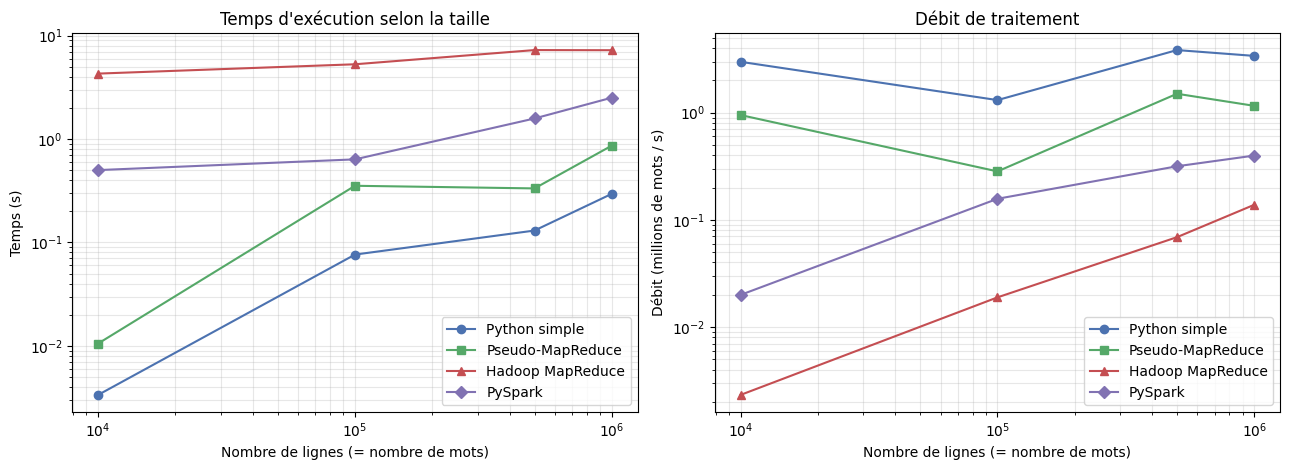

In [11]:
import matplotlib.pyplot as plt

methodes = [("Python simple (s)",     "Python simple",    "o", "#4C72B0"),
            ("Pseudo-MapReduce (s)",  "Pseudo-MapReduce", "s", "#55A868"),
            ("Hadoop MapReduce (s)",  "Hadoop MapReduce", "^", "#C44E52"),
            ("PySpark (s)",           "PySpark",          "D", "#8172B2")]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for col, nom, marqueur, couleur in methodes:
    if df[col].notna().any():
        ax1.plot(df["lignes"], df[col], marker=marqueur, color=couleur, label=nom)
        ax2.plot(df["lignes"], df["lignes"] / df[col] / 1e6, marker=marqueur, color=couleur, label=nom)

ax1.set(xscale="log", yscale="log", xlabel="Nombre de lignes (= nombre de mots)",
        ylabel="Temps (s)", title="Temps d'exécution selon la taille")
ax2.set(xscale="log", yscale="log", xlabel="Nombre de lignes (= nombre de mots)",
        ylabel="Débit (millions de mots / s)", title="Débit de traitement")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

In [12]:
# Chiffres clés calculés à partir du tableau ci-dessus (utilisés dans l'analyse)
premier, dernier = df.iloc[0], df.iloc[-1]
print(f"Taille multipliée par {dernier['lignes'] / premier['lignes']:.0f} (de {int(premier['lignes']):,} à {int(dernier['lignes']):,} lignes)\n")
for col, nom in [("Python simple (s)", "Python simple"), ("Pseudo-MapReduce (s)", "Pseudo-MapReduce"),
                 ("Hadoop MapReduce (s)", "Hadoop"), ("PySpark (s)", "PySpark")]:
    if df[col].notna().all():
        print(f"  {nom:<17}: temps multiplié par {dernier[col] / premier[col]:6.1f}   "
              f"({premier[col]:.4f} s -> {dernier[col]:.4f} s)")

print(f"\nSurcoût pseudo-MapReduce / Python : de {df['Pseudo-MR / Simple'].min():.1f}x à {df['Pseudo-MR / Simple'].max():.1f}x")
if df["Hadoop / Simple"].notna().all():
    print(f"Hadoop / Python                   : de {df['Hadoop / Simple'].max():.0f}x (petit fichier) à {df['Hadoop / Simple'].min():.0f}x (gros fichier)")
if df["PySpark / Simple"].notna().all():
    print(f"PySpark / Python                  : de {df['PySpark / Simple'].max():.1f}x (petit fichier) à {df['PySpark / Simple'].min():.1f}x (gros fichier)")
    mieux = df.loc[df["PySpark (s)"] < df["Python simple (s)"], "lignes"]
    print("PySpark plus rapide que Python simple à partir de :",
          f"{int(mieux.min()):,} lignes" if len(mieux) else "jamais sur les tailles testées")
    if df["Hadoop MapReduce (s)"].notna().all():
        print(f"PySpark plus rapide que Hadoop sur {int((df['PySpark (s)'] < df['Hadoop MapReduce (s)']).sum())} tailles sur {len(df)}")
print(f"\nDémarrage de la session Spark (payé une seule fois) : {T_DEMARRAGE_SPARK:.1f} s")

Taille multipliée par 100 (de 10,000 à 1,000,000 lignes)

  Python simple    : temps multiplié par   88.0   (0.0034 s -> 0.2954 s)
  Pseudo-MapReduce : temps multiplié par   82.1   (0.0105 s -> 0.8641 s)
  Hadoop           : temps multiplié par    1.7   (4.2955 s -> 7.2308 s)
  PySpark          : temps multiplié par    5.0   (0.5010 s -> 2.5137 s)

Surcoût pseudo-MapReduce / Python : de 2.6x à 4.6x
Hadoop / Python                   : de 1280x (petit fichier) à 24x (gros fichier)
PySpark / Python                  : de 149.3x (petit fichier) à 8.3x (gros fichier)
PySpark plus rapide que Python simple à partir de : jamais sur les tailles testées
PySpark plus rapide que Hadoop sur 4 tailles sur 4

Démarrage de la session Spark (payé une seule fois) : 12.9 s


### Lecture des résultats

(Les ordres de grandeur ci-dessous se vérifient avec le tableau et les chiffres clés juste au-dessus.)

- **Python simple vs pseudo-MapReduce.** Les deux temps croissent à peu près proportionnellement à la taille du fichier. Dès que le fichier dépasse quelques dizaines de milliers de lignes, le pseudo-MapReduce est plus lent d'un facteur de l'ordre de 2 à 4 (colonne `Pseudo-MR / Simple`) : il construit une liste de toutes les paires `(mot, 1)`, puis une liste de `1` par mot dans `shuffle`, avant de les additionner. Ce surcoût porte aussi sur la **mémoire**, qui devient le facteur limitant sur de gros fichiers.
- **Hadoop : un coût fixe qui s'amortit.** Chaque job paie un coût fixe de plusieurs secondes (démarrage de la JVM, préparation des tâches Map et Reduce, écriture du résultat, et copie vers HDFS quand HDFS est actif). Sur les petits fichiers, ce coût écrase le temps utile : le rapport initial mesurait 12 s contre 0,012 s en Python, soit un facteur d'environ 1000. Quand la taille augmente, le temps Hadoop croît **beaucoup plus lentement** que celui de Python, donc le rapport `Hadoop / Simple` baisse.
- **PySpark : un coût fixe bien plus faible que Hadoop.** La session Spark ne démarre qu'une fois (quelques secondes, mesurées à part). Ensuite, chaque comptage ne paie qu'un petit coût de planification des tâches, sans relancer de JVM ni écrire de fichiers intermédiaires : PySpark est donc nettement plus rapide que Hadoop sur les petits fichiers. En revanche, sur des fichiers de quelques Mo, il reste en général **plus lent que Python simple** : les lambdas Python sont exécutées par des processus Python séparés, et l'échange des données entre la JVM et Python (sérialisation) pèse plus lourd que le comptage lui-même. Son temps croît cependant plus lentement que celui de Python, grâce au parallélisme et à la pré-agrégation de `reduceByKey` ; il ne rattrape Python que si le fichier est assez grand et que la machine a assez de cœurs.

> **Limite de ces mesures.** Hadoop et Spark tournent ici sur **une seule machine** (peu de cœurs sur Colab), sur des fichiers de quelques Mo. Leur vrai avantage (parallélisme sur plusieurs nœuds, tolérance aux pannes, données plus grandes que la RAM d'une machine) n'apparaît qu'avec un cluster et des volumes de l'ordre du Go ou plus. Ces expériences mesurent surtout les **coûts fixes** de chaque outil.

## 6. Conclusion

| Critère | Python simple | Pseudo-MapReduce | Hadoop MapReduce | PySpark |
|---|---|---|---|---|
| Mise en œuvre | quelques lignes | quelques fonctions | installation et configuration lourdes | `pip install pyspark` + Java |
| Petits fichiers (Ko à quelques Mo) | **le plus rapide** | rapide, 2 à 4 fois plus lent | très lent (coût fixe de plusieurs secondes par job) | démarrage de quelques secondes, puis jobs rapides mais plus lents que Python |
| Fichiers moyens (dizaines à centaines de Mo) | rapide si la RAM suffit | plus lent et gourmand en mémoire | coût fixe amorti, mais pas de gain sans cluster | **exploite tous les cœurs**, calcul en mémoire |
| Très gros volumes (Go à To, > RAM) | **impossible** (mémoire) | **impossible** (paires en mémoire) | **adapté** : blocs HDFS, parallélisme, tolérance aux pannes | **adapté** sur un cluster, en général plus rapide que Hadoop (calcul en mémoire) |
| Intérêt pédagogique | référence | comprendre map / shuffle / reduce | MapReduce « historique » | MapReduce moderne, API concise |

**Ce qu'il faut retenir**
1. Les quatre méthodes produisent **exactement le même résultat** ; seule change la manière de calculer.
2. Le **choix dépend de la taille des données** : Python suffit tant que tout tient en mémoire sur une machine ; Hadoop et Spark apportent la **scalabilité** quand ce n'est plus le cas.
3. Hadoop et Spark ne sont pas « plus rapides » par nature : ils ont un **coût fixe** (très élevé pour Hadoop, plus faible pour Spark) qui n'est rentabilisé que sur de gros volumes et plusieurs nœuds.
4. Spark garde le modèle MapReduce mais **travaille en mémoire** et réutilise sa session : c'est ce qui explique qu'il soit nettement plus rapide que Hadoop sur des fichiers de cette taille (voir le tableau), même s'il ne bat pas Python simple à cette échelle.
5. Le pseudo-MapReduce sert à **comprendre** le modèle ; il n'apporte aucun gain tant qu'il n'est pas réellement distribué.


In [13]:
# Libère les ressources de Spark
if SPARK_OK:
    spark.stop()